# Lights Out · Phase 4 drivers and what-if

**Q11.** Why? What drove the 2026 cuts: less fuel, more demand, or both?
**Q2 and Q4.** How much is gas worth, and which lever would have helped most: more gas, more supply of any kind, more solar, or evening savings?
**Q7.** When does it hit? Why the deepest cuts come at night.

Built by `04_model/drivers.py`. Every split here is an exact identity: cut = demand minus generation, and generation is
the sum of its sources. Nothing is modelled except the demand and temperature check.

In [1]:
import duckdb, pandas as pd, numpy as np, matplotlib.pyplot as plt
con = duckdb.connect('../01_data/processed/lights_out.duckdb', read_only=True); q = lambda s: con.sql(s).df()
pd.set_option('display.width', 160)
CARD, GREEN, GREEN2, OCHRE, TOMATO, SLATE, INK, GRID = '#F7F1E6','#1D4A35','#3B8A60','#B87318','#F2462E','#7D8D99','#16382A','#E6DCC8'
plt.rcParams.update({'figure.facecolor': CARD, 'axes.facecolor': CARD, 'axes.edgecolor': GRID, 'axes.labelcolor': INK,
    'xtick.color': '#4F5E52', 'ytick.color': '#4F5E52', 'axes.grid': True, 'grid.color': GRID, 'axes.spines.top': False,
    'axes.spines.right': False, 'font.size': 10.5, 'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlecolor': GREEN,
    'axes.titlelocation': 'left', 'figure.dpi': 110})
PARTS = [('from_demand_mw', 'demand rose'), ('from_gas_mw', 'gas'), ('from_coal_mw', 'coal'), ('from_oil_mw', 'oil'),
         ('from_imports_mw', 'imports'), ('from_hydro_solar_wind_mw', 'hydro, solar, wind'), ('from_other_mw', 'other')]

## Q11. The crisis: August and September 2026 against the same months of 2025

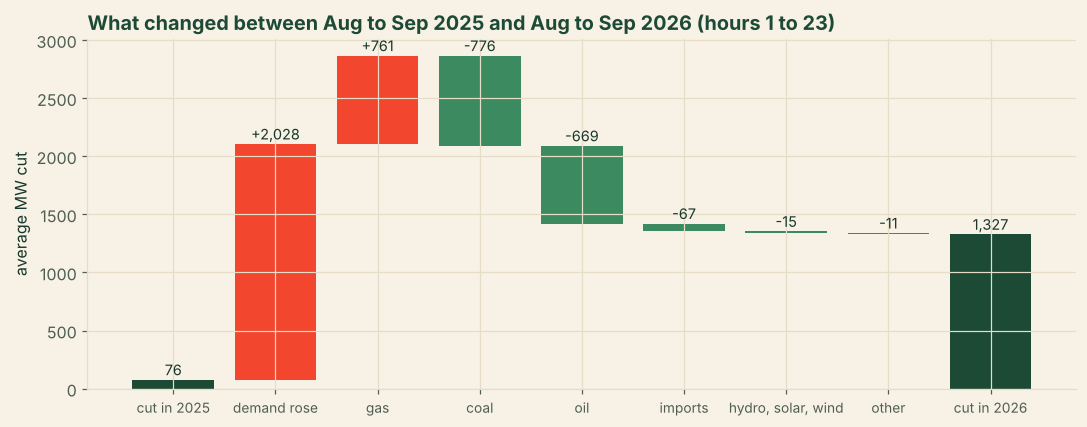

,cut_before_mw,cut_now_mw,change_in_cut_mw,from_demand_mw,from_gas_mw,from_coal_mw,from_oil_mw,from_imports_mw,from_hydro_solar_wind_mw,from_other_mw
period,,,,,,,,,,
all hours (1 to 23),76,1327,1251,2028,761,-776,-669,-67,-15,-11
evening (18 to 22),129,1262,1133,1986,782,-663,-830,-135,-8,0
night (1 to 5),82,1810,1727,2111,773,-630,-589,62,-2,3
daytime (9 to 16),46,1163,1117,1999,761,-873,-601,-105,-31,-33


In [2]:
b = q("SELECT * FROM drivers.bridge_crisis").set_index('period')
r = b.loc['all hours (1 to 23)']
steps = [('cut in 2025', r.cut_before_mw)] + [(lab, r[c]) for c, lab in PARTS if abs(r[c]) >= 5] + [('cut in 2026', r.cut_now_mw)]
fig, ax = plt.subplots(figsize=(10, 4)); run = 0
for i, (lab, v) in enumerate(steps):
    if i in (0, len(steps) - 1):
        ax.bar(i, v, color=GREEN); top = v; run = v if i == 0 else run; txt = f"{v:,.0f}"
    else:
        bottom = run if v >= 0 else run + v
        ax.bar(i, abs(v), bottom=bottom, color=TOMATO if v > 0 else GREEN2); top = bottom + abs(v); run += v; txt = f"{v:+,.0f}"
    ax.text(i, top + 40, txt, ha='center', fontsize=9.5, color=INK)
ax.set_xticks(range(len(steps)), [s[0] for s in steps], fontsize=9); ax.set_ylabel('average MW cut')
ax.set_title('What changed between Aug to Sep 2025 and Aug to Sep 2026 (hours 1 to 23)'); plt.tight_layout(); plt.show()
b[['cut_before_mw', 'cut_now_mw', 'change_in_cut_mw'] + [c for c, _ in PARTS]].round(0).astype(int)

**How to read it.** Red pushes the cut up, green pulls it down. Demand rose by about 2,000 MW and gas fell by about
760 MW. Coal and oil plants made up most of the gas loss but not the extra demand. Imports did not grow.

The demand line needs care. In 2026, "demand" is generation plus PGCB's own cut estimate. So part of the rise could
come from how the cut is estimated rather than from use. The next section checks it against the weather.

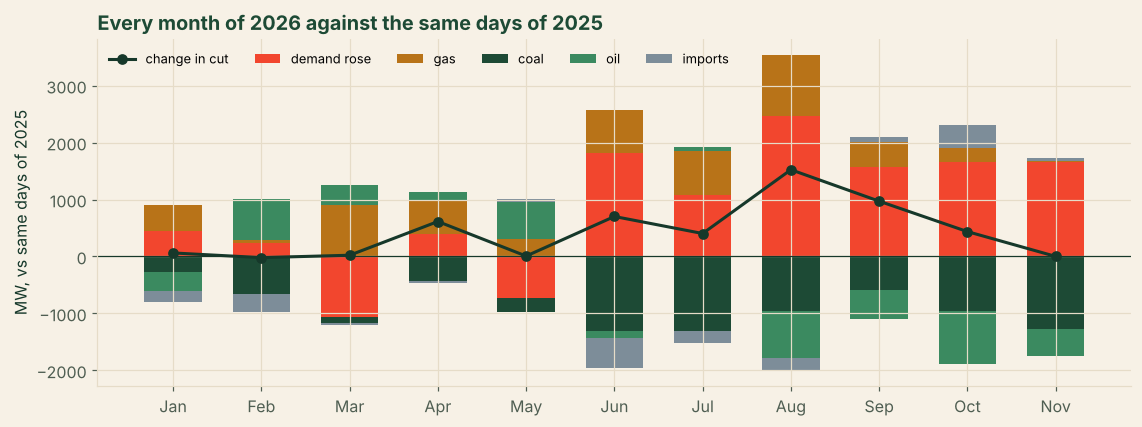

In [3]:
m = q("SELECT * FROM drivers.bridge_monthly WHERE year = 2026 ORDER BY month")
fig, ax = plt.subplots(figsize=(10.5, 4)); x = np.arange(len(m)); pos = np.zeros(len(m)); neg = np.zeros(len(m))
cols = {'from_demand_mw': TOMATO, 'from_gas_mw': OCHRE, 'from_coal_mw': GREEN, 'from_oil_mw': GREEN2, 'from_imports_mw': SLATE}
for c, lab in PARTS[:5]:
    v = m[c].values; base = np.where(v >= 0, pos, neg)
    ax.bar(x, v, bottom=base, color=cols[c], label=lab, width=.65); pos += np.clip(v, 0, None); neg += np.clip(v, None, 0)
ax.plot(x, m.change_in_cut_mw, 'o-', color=INK, lw=2, label='change in cut')
ax.set_xticks(x, pd.to_datetime(m.period).dt.strftime('%b')); ax.axhline(0, color=INK, lw=.8)
ax.set_ylabel('MW, vs same days of 2025'); ax.set_title('Every month of 2026 against the same days of 2025')
ax.legend(frameon=False, ncol=6, fontsize=8.5, loc='upper left'); plt.tight_layout(); plt.show()

From June on, reported demand runs 1,000 to 2,500 MW above the same days of 2025 in every month. Coal grew
every month (new plants); gas fell in the crisis months. Is that extra demand real? The next section checks it
against the weather.

## Demand and temperature

In [4]:
tabs = set(q("SELECT table_name FROM duckdb_tables() WHERE schema_name = 'drivers'").table_name)
if 'demand_temp_check' in tabs:
    fit = q("SELECT * FROM drivers.demand_temp_fit"); chk = q("SELECT * FROM drivers.demand_temp_check ORDER BY year, month")
    print(f"Fit on Apr to Oct 2023 to 2025 workdays: {fit.mw_per_degree_feels_like_above_30[0]:,.0f} MW per °C of 'feels like' above 30 °C, "
          f"plus {fit.mw_growth_per_year[0]:,.0f} MW of growth a year (typical miss {fit.residual_sd_mw[0]:,.0f} MW).")
    show = chk[chk.year >= 2025].copy(); show['month'] = pd.to_datetime(show[['year','month']].assign(day=1)).dt.strftime('%b %Y')
    display(show[['month', 'days', 'feels_max', 'expected_peak', 'reported_peak', 'served_peak', 'gap_reported_vs_expected']].round(0))
else:
    print('Weather not loaded yet: run tools\\weather_collect.py, then 04_model\\drivers.py, then rerun this notebook.')

Fit on Apr to Oct 2023 to 2025 workdays: 272 MW per °C of 'feels like' above 30 °C, plus 536 MW of growth a year (typical miss 838 MW).


,month,days,feels_max,expected_peak,reported_peak,served_peak,gap_reported_vs_expected
14,Apr 2025,22,38.0,15138.0,14753.0,14670.0,-385.0
15,May 2025,21,38.0,15221.0,15118.0,14983.0,-103.0
16,Jun 2025,22,38.0,15108.0,14755.0,14719.0,-352.0
17,Jul 2025,23,37.0,14928.0,15121.0,15023.0,193.0
18,Aug 2025,21,37.0,15050.0,15329.0,15279.0,279.0
19,Sep 2025,22,39.0,15419.0,15697.0,15428.0,278.0
20,Oct 2025,22,37.0,14949.0,14785.0,14601.0,-165.0
21,Apr 2026,22,36.0,15077.0,14715.0,13887.0,-361.0
22,May 2026,16,37.0,15428.0,15259.0,15052.0,-169.0
23,Jun 2026,22,39.0,15991.0,16710.0,15548.0,719.0


**What the weather says.**
- Summer 2026 was not unusually hot. August's average daily "feels like" peak was 37.7 °C against 37.5 °C in 2025.
- The peak the grid actually **served** in 2026 matches what the 2023 to 2025 weather pattern and normal growth
  (about 540 MW a year) expect, within a few hundred MW in every month.
- The **reported** peak demand in August and September ran about 2,000 MW above that. Reported demand is generation
  plus PGCB's own estimate of the cut, so this gap is the estimate, not a measurement. It may include real demand that
  could not be met; it may also be set high. We present the cut as "PGCB's estimate" throughout.
- After the crisis, in October and early November, the grid served roughly 800 to 900 MW more than weather and normal
  growth explain, with few cuts. That is real new load on the grid. One possible source is factories moving from
  their own gas generators to the grid as their gas was rationed; this data cannot confirm it.

## Q1 again. The closing rules, with weather taken out

In [5]:
if 'policy_check_weather' in tabs:
    p = q("SELECT * FROM drivers.policy_check_weather ORDER BY rule_date")
    lo, hi = p.noise_low_mw[0], p.noise_high_mw[0]
    print(f"Normal swing at a random 2025 date (90% of placebo dates): {lo:,.0f} to {hi:,.0f} MW")
    display(p[['rule_date', 'event', 'raw_mw', 'weather_adjusted_mw', 'beyond_noise']].round(0))


Normal swing at a random 2025 date (90% of placebo dates): -643 to 567 MW


/tmp/ipykernel_394/1393265438.py:5: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(p[['rule_date', 'event', 'raw_mw', 'weather_adjusted_mw', 'beyond_noise']].round(0))


,rule_date,event,raw_mw,weather_adjusted_mw,beyond_noise
0,2026-04-02,Shop owners' association: shops and malls clos...,-440.0,-511.0,False
1,2026-04-03,Government: shops and malls close by 6 pm,-246.0,-238.0,False
2,2026-04-05,Closing relaxed to 7 pm; government offices 9 ...,-217.0,-141.0,False
3,2026-05-12,Closing extended to 10 pm until Eid-ul-Azha,75.0,-153.0,False
4,2026-06-01,Markets and malls closed after 7 pm; decorativ...,-164.0,-224.0,False
5,2026-06-11,Power Division: markets may open until 9 pm,524.0,533.0,False
6,2026-08-13,"Shops, markets and malls open 11 am to 8 pm; b...",194.0,167.0,False


Taking the weather out does not change the Phase 2 answer. The April package looks a little larger (about
510 MW lower in the evening) and the 11 June relaxation shows evening demand rising by about 530 MW, both in the
expected direction, but none of the seven changes is beyond the normal swing at a random date. The rules may have
helped; this data cannot show it. Hourly feeder or shop-level metering would.

## Q7. Why the deepest cuts come at night

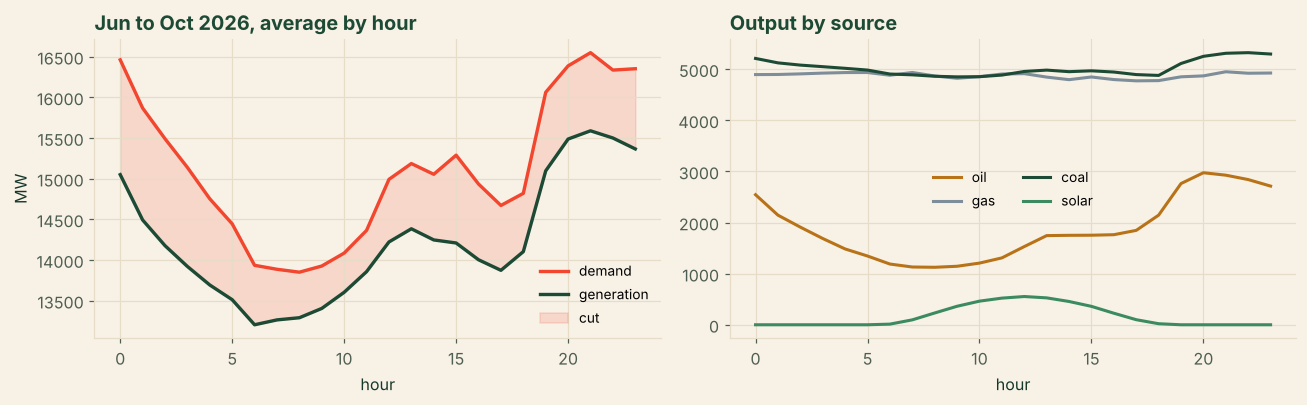

Midnight to 3 am: demand 15,739 MW, oil 2,071 MW; 8 to 10 pm: demand 16,424 MW, oil 2,913 MW


In [6]:
e = q("SELECT * FROM drivers.evening_gap ORDER BY hour")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8))
a1.plot(e.hour, e.true_demand_mw, color=TOMATO, lw=2.2, label='demand'); a1.plot(e.hour, e.generation_mw, color=GREEN, lw=2.2, label='generation')
a1.fill_between(e.hour, e.generation_mw, e.true_demand_mw, color=TOMATO, alpha=.15, label='cut')
a1.set_title('Jun to Oct 2026, average by hour'); a1.set_xlabel('hour'); a1.set_ylabel('MW'); a1.legend(frameon=False, fontsize=9)
for c, col, lab in [('liquid_fuel', OCHRE, 'oil'), ('gas', SLATE, 'gas'), ('coal', GREEN, 'coal'), ('solar', GREEN2, 'solar')]:
    a2.plot(e.hour, e[c], color=col, lw=2, label=lab)
a2.set_title('Output by source'); a2.set_xlabel('hour'); a2.legend(frameon=False, fontsize=9, ncol=2); plt.tight_layout(); plt.show()
print(f"Midnight to 3 am: demand {e.true_demand_mw[0:4].mean():,.0f} MW, oil {e.liquid_fuel[0:4].mean():,.0f} MW; "
      f"8 to 10 pm: demand {e.true_demand_mw[20:23].mean():,.0f} MW, oil {e.liquid_fuel[20:23].mean():,.0f} MW")

**What the data shows.** Demand stays above 15,000 MW until about 3 am (cooling through hot nights), but oil plants
step down after 10 pm, from about 2,900 MW to about 1,300 MW by 5 am, while gas, coal and imports stay flat. So the
deepest cuts, around midnight to 2 am, come while demand is still high and oil is being turned down. The data cannot say why oil is stepped down at night (fuel cost, fuel stocks or plant limits); the load
dispatch centre can. The night cut falls hardest on homes and on rural feeders, where people are asleep and cannot
complain in real time.

## Q2 and Q4. Which lever helps most? (applied to every real hour of 2026)

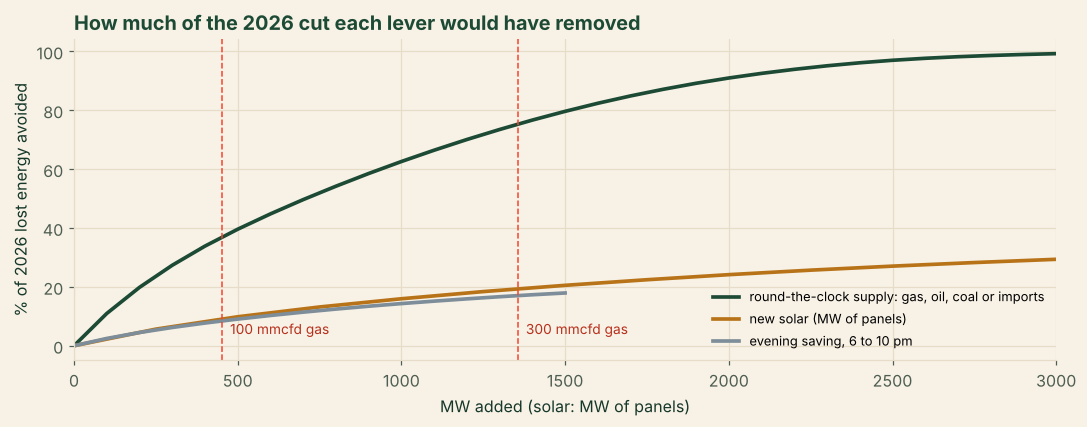

,lever,amount,energy_cut_gwh,energy_avoided,hours_with_cut_500,peak_cut_mw
4,extra gas (mmcfd),100.0,2473.0,37%,1595,3305.0
8,extra gas (mmcfd),200.0,1620.0,59%,1198,2853.0
12,extra gas (mmcfd),300.0,969.0,75%,797,2402.0
20,extra gas (mmcfd),500.0,209.0,95%,160,1498.0
30,extra flat supply (MW),100.0,3490.0,11%,1972,3657.0
32,extra flat supply (MW),300.0,2848.0,27%,1734,3457.0
34,extra flat supply (MW),500.0,2368.0,40%,1555,3257.0
39,extra flat supply (MW),1000.0,1466.0,63%,1121,2757.0
49,extra flat supply (MW),2000.0,353.0,91%,302,1757.0
62,extra solar (MW),500.0,3534.0,10%,1972,3757.0


In [7]:
w = q("SELECT * FROM drivers.what_if"); gc = q("SELECT * FROM drivers.gas_conversion")
central = gc.mw_per_mmcfd[1]
fig, ax = plt.subplots(figsize=(10, 4))
labels = {'extra flat supply (MW)': 'round-the-clock supply: gas, oil, coal or imports', 'extra solar (MW)': 'new solar (MW of panels)',
          'evening saving 18 to 22 (MW)': 'evening saving, 6 to 10 pm'}
for lever, col in [('extra flat supply (MW)', GREEN), ('extra solar (MW)', OCHRE), ('evening saving 18 to 22 (MW)', SLATE)]:
    d = w[w.lever == lever]; ax.plot(d.amount, d.energy_avoided_share * 100, color=col, lw=2.4, label=labels[lever])
for mmcfd in (100, 300):
    ax.axvline(mmcfd * central, color=TOMATO, lw=1, ls='--'); ax.text(mmcfd * central + 25, 4, f'{mmcfd} mmcfd gas', color='#B8301C', fontsize=9)
ax.set_xlim(0, 3000); ax.set_xlabel('MW added (solar: MW of panels)'); ax.set_ylabel('% of 2026 lost energy avoided')
ax.set_title('How much of the 2026 cut each lever would have removed'); ax.legend(frameon=False, fontsize=8.5); plt.tight_layout(); plt.show()
pick = w[w.amount.isin([100, 300, 500, 1000, 2000]) & ~w.lever.str.contains('gas') | w.amount.isin([100, 200, 300, 500]) & w.lever.str.contains('gas')]
pick.assign(energy_avoided=pick.energy_avoided_share.map('{:.0%}'.format))[['lever', 'amount', 'energy_cut_gwh', 'energy_avoided', 'hours_with_cut_500', 'peak_cut_mw']].round(0)

In [8]:
gc.round(1)

,case,heat_rate_btu_per_kwh,mw_per_mmcfd
0,"low (old plants, 12,000 Btu/kWh)",12000,3.6
1,"central (fleet mix, 9,500 Btu/kWh)",9500,4.5
2,"high (combined cycle, 7,500 Btu/kWh)",7500,5.7


**What it says.**
- **Round-the-clock supply is what works.** 1,000 MW more at every hour, from any source, removes about 60% of the
  year's lost energy. The first few hundred MW do the most, because most cut hours are shallow.
- **Gas is the cheapest way to get it.** At about 4.5 MW per mmcfd, the first 100 mmcfd sent to power plants (about
  450 MW) removes about 37%; 300 mmcfd removes about 75%. The conversion is an engineering estimate; Petrobangla's
  daily gas allocation to power would let us check it.
- **Solar alone barely touches it.** 1,000 MW of new panels removes about 16% and leaves the worst hour unchanged,
  because the deepest cuts are at night. Solar helps if it frees gas by day for the night (storage or gas held back).
- **Evening savings are small.** A 500 MW saving from 6 to 10 pm (for example shop closing rules) removes about 9%,
  which fits the Phase 2 finding that the closing rules showed no effect beyond normal swings.